In [7]:
!pip install -q xgboost shap imbalanced-learn scikit-optimize openpyxl

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pathlib
import re

from scipy import stats

from sklearn.model_selection import (
    train_test_split, GridSearchCV, KFold, RandomizedSearchCV, cross_val_score
)
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

from xgboost import XGBRegressor
from skopt import BayesSearchCV
from skopt.space import Integer, Real
from imblearn.over_sampling import SMOTENC
import shap

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

FIG_DIR = "plots"
OUT_DIR = "output"
pathlib.Path(FIG_DIR).mkdir(parents=True, exist_ok=True)
pathlib.Path(OUT_DIR).mkdir(parents=True, exist_ok=True)

(46685, 9)

Missing values
Model           1
Make            1
YOM             1
Color           1
Used            1
Transmission    1
Mileage         1
Location        1
Price           1
dtype: int64


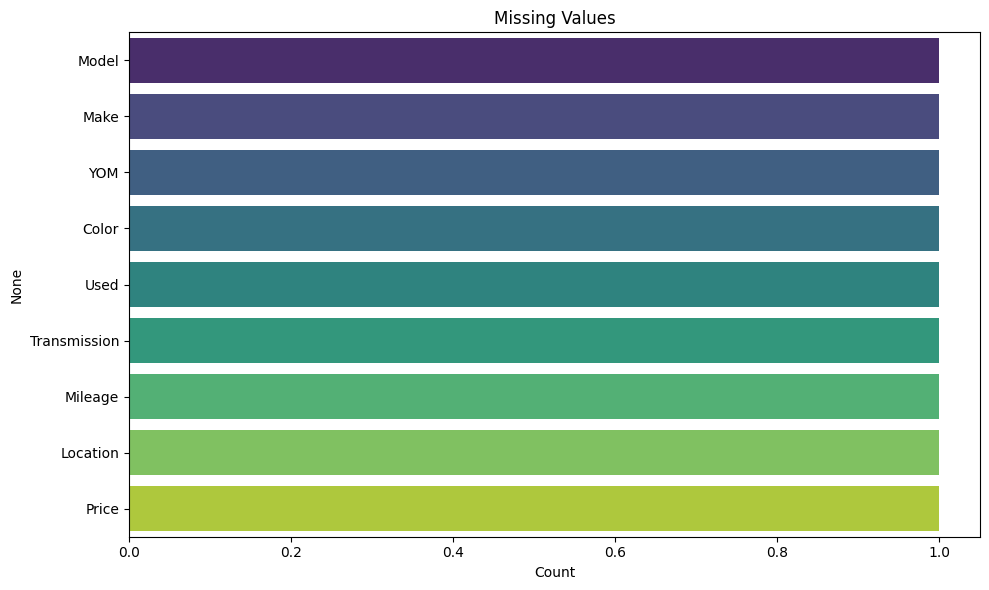

Duplicate Rows: 7549


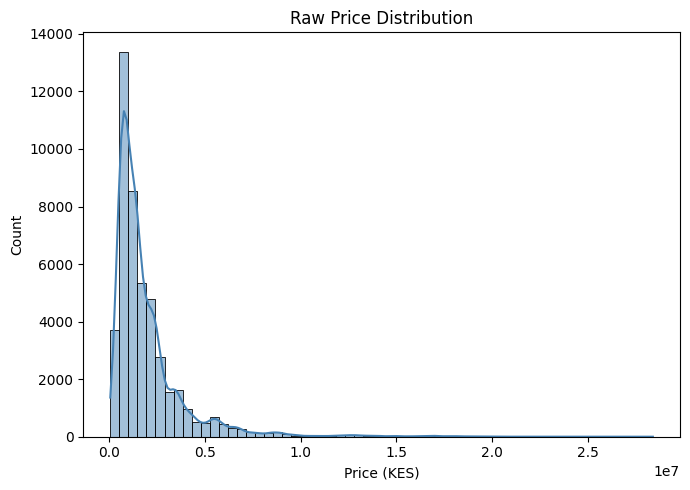

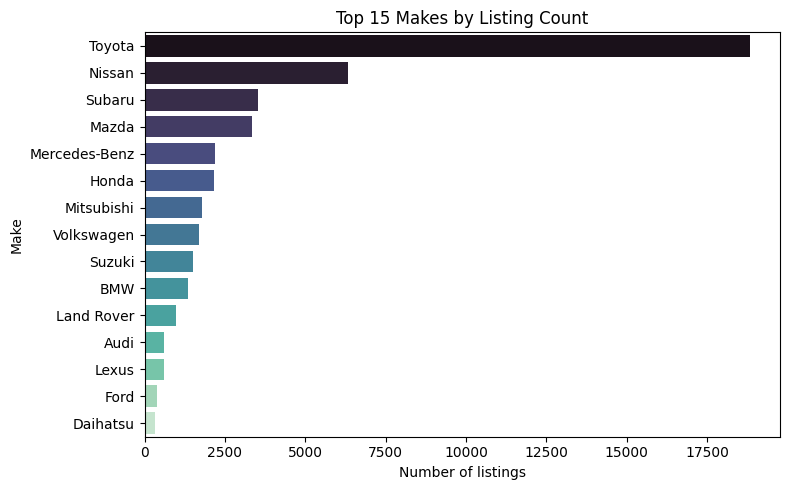

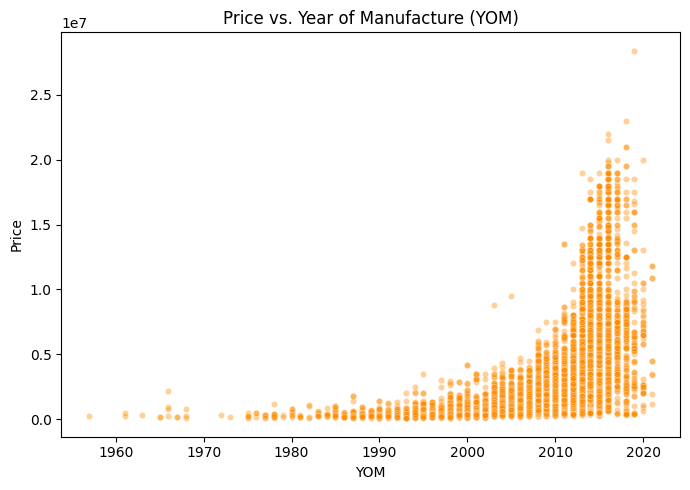

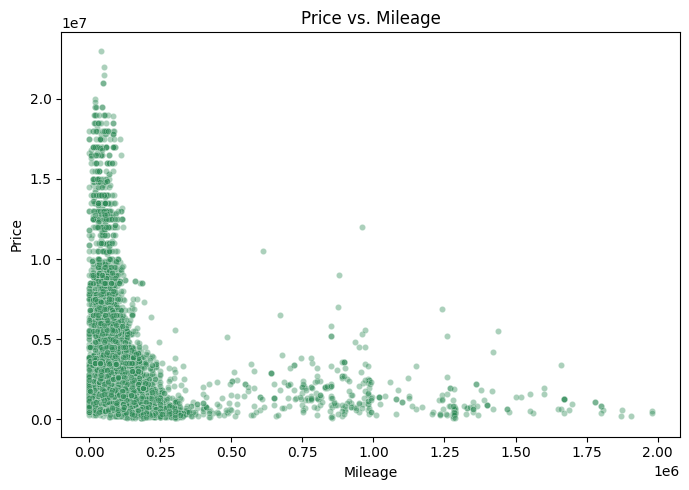

In [8]:
df_raw = pd.read_excel('Vehicle_Data.xlsx')

print(df_raw.shape)
df_raw.head()
df_raw.describe(include='all')

print("\nMissing values")
missing = df_raw.isnull().sum().sort_values(ascending=False)
print(missing)

plt.figure(figsize=(10,6))
sns.barplot(x=missing.values, y=missing.index, palette="viridis")
plt.title("Missing Values"); plt.xlabel("Count"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/missing_values.png"); plt.show()

print("Duplicate Rows:", df_raw.duplicated().sum())


_price_num = pd.to_numeric(
    df_raw["Price"].astype(str).str.replace("KSh", "", regex=False).str.replace(",", "", regex=False).str.strip(),
    errors="coerce"
)
_mileage_num = pd.to_numeric(
    df_raw["Mileage"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)
_yom_num = pd.to_numeric(df_raw["YOM"], errors="coerce")

plt.figure(figsize=(7, 5))
sns.histplot(_price_num.dropna(), bins=60, kde=True, color="steelblue")
plt.title("Raw Price Distribution"); plt.xlabel("Price (KES)"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/raw_price_distribution.png"); plt.show()

plt.figure(figsize=(8, 5))
top_makes = df_raw["Make"].value_counts().head(15)
sns.barplot(x=top_makes.values, y=top_makes.index, palette="mako")
plt.xlabel("Number of listings"); plt.title("Top 15 Makes by Listing Count"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/top_makes.png"); plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(x=_yom_num, y=_price_num, alpha=0.4, s=20, color="darkorange")
plt.title("Price vs. Year of Manufacture (YOM)"); plt.xlabel("YOM"); plt.ylabel("Price"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/price_vs_yom.png"); plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(x=_mileage_num, y=_price_num, alpha=0.4, s=20, color="seagreen")
plt.title("Price vs. Mileage"); plt.xlabel("Mileage"); plt.ylabel("Price"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/price_vs_mileage.png"); plt.show()

In [9]:
df = df_raw.copy()

# Remove duplicate listings

n_before_dedup = len(df)
df = df.drop_duplicates().copy()
print(f"Removed {n_before_dedup - len(df)} duplicate rows (kept {len(df)})")

# Make/Model canonicalization

def _canonicalize_spelling(series):
    """Map every case/whitespace variant of a value to its most frequent
    raw spelling (e.g. 'Bmw' and 'BMW' both -> 'BMW', whichever is modal)."""
    s = series.astype(str).str.strip()
    vc = s.value_counts().rename_axis("value").reset_index(name="count")
    vc["key"] = vc["value"].str.lower()
    modal_map = vc.sort_values("count", ascending=False).drop_duplicates("key").set_index("key")["value"]
    return s.str.lower().map(modal_map)

df["Make"] = _canonicalize_spelling(df["Make"])
df["Model"] = _canonicalize_spelling(df["Model"])

# Known two-word makes mis-split at the space during scraping
SPLIT_BRAND_FIX = {"Land": "Land Rover", "Alfa": "Alfa Romeo"}
df["Make"] = df["Make"].replace(SPLIT_BRAND_FIX)

# Structural corruption filter

VALID_USED = {"foreign used", "kenyan used", "brand new"}
VALID_TRANS = {"automatic", "manual", "cvt", "amt"}

def _valid_yom(x):
    try:
        y = float(x)
        return 1960 <= y <= 2026
    except (TypeError, ValueError):
        return False

def _valid_used(x):
    return str(x).strip().lower() in VALID_USED

def _valid_trans(x):
    return str(x).strip().lower() in VALID_TRANS

def _valid_mileage(x):
    if str(x).strip().lower() == "unavailable":
        return True
    try:
        float(str(x).replace(",", ""))
        return True
    except (TypeError, ValueError):
        return False

def _valid_price(x):
    return bool(re.match(r"^\s*KSh", str(x)))

good_mask = (
    df["YOM"].apply(_valid_yom)
    & df["Used"].apply(_valid_used)
    & df["Transmission"].apply(_valid_trans)
    & df["Mileage"].apply(_valid_mileage)
    & df["Price"].apply(_valid_price)
)
n_before_struct = len(df)
df.loc[~good_mask].to_csv(f"{OUT_DIR}/structurally_corrupted_rows.csv", index=False)
df = df.loc[good_mask].copy()
print(f"Structural corruption filter: dropped {n_before_struct - len(df)} rows "
      f"({(n_before_struct - len(df)) / n_before_struct * 100:.2f}%)")

# Numeric parsing
df["Price"] = (
    df["Price"].astype(str)
    .str.replace("KSh", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .astype(float)
)
df["Mileage"] = df["Mileage"].replace("Unavailable", np.nan)
df["Mileage"] = pd.to_numeric(df["Mileage"].astype(str).str.replace(",", "", regex=False), errors="coerce")
df["YOM"] = pd.to_numeric(df["YOM"], errors="coerce")

# DEBUG: check impact of missing Mileage before dropping
n_before = len(df)
missing_mileage = df["Mileage"].isna()
print(f"\nRows with missing Mileage: {missing_mileage.sum()} "
      f"({missing_mileage.mean()*100:.2f}% of {n_before})")
print("\nMake share among rows about to be dropped for missing Mileage (top 10):")
print((df.loc[missing_mileage, "Make"].value_counts(normalize=True).head(10) * 100).round(2))
print("\nMake share overall (top 10):")
print((df["Make"].value_counts(normalize=True).head(10) * 100).round(2))

# drop rows missing any critical field, INCLUDING Mileage
df = df.dropna(subset=["Price", "Make", "Model", "YOM", "Mileage"])
n_after = len(df)
print(f"\nRows before: {n_before}  Rows after: {n_after}  Dropped: {n_before - n_after}")
assert df["Mileage"].isna().sum() == 0, "Mileage still has nulls after dropna"

# Price cap + IQR outlier trim (on log scale)
PRICE_UPPER_LIMIT = 10_000_000
df.loc[df["Price"] > PRICE_UPPER_LIMIT, ["Model", "Make", "YOM", "Price"]] \
  .to_csv(f"{OUT_DIR}/suspect_price_over_10m_review.csv", index=False)
df = df[df["Price"] <= PRICE_UPPER_LIMIT]

log_price = np.log1p(df["Price"])
q1, q3 = log_price.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = np.expm1(q1 - 1.5 * iqr), np.expm1(q3 + 1.5 * iqr)
df = df[(df["Price"] >= lower) & (df["Price"] <= upper)]

# Categorical normalization
df["Condition"] = df["Used"].str.strip().str.title()
df["Transmission"] = df["Transmission"].str.strip().str.title()
df["County"] = df["Location"].str.split(",").str[0].str.strip()
df["County"] = df["County"].fillna(df["County"].mode()[0])

# Derived features
CURRENT_YEAR = 2026
df["Car_Age"] = CURRENT_YEAR - df["YOM"]
df["Mileage_Per_Year"] = df["Mileage"] / df["Car_Age"].replace(0, 1)
df["Log_Price"] = np.log1p(df["Price"])
df["Log_Mileage"] = np.log1p(df["Mileage"])

Removed 7549 duplicate rows (kept 39136)
Structural corruption filter: dropped 332 rows (0.85%)

Rows with missing Mileage: 6582 (16.96% of 38804)

Make share among rows about to be dropped for missing Mileage (top 10):
Make
Toyota           37.45
Nissan           14.42
Subaru            7.67
Mazda             7.35
Mitsubishi        4.82
Honda             4.82
Mercedes-Benz     4.54
Volkswagen        3.62
Suzuki            3.33
BMW               2.73
Name: proportion, dtype: float64

Make share overall (top 10):
Make
Toyota           42.61
Nissan           12.77
Subaru            6.87
Mazda             6.44
Honda             4.67
Mitsubishi        3.98
Volkswagen        3.85
Mercedes-Benz     3.77
Suzuki            3.41
BMW               3.16
Name: proportion, dtype: float64

Rows before: 38804  Rows after: 32222  Dropped: 6582


In [10]:
df["MakeModel"] = df["Make"] + "_" + df["Model"]
train_df, test_df = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)

def kfold_target_encode(train, test, column, target, n_splits=5, seed=RANDOM_STATE):
    train = train.copy(); test = test.copy()
    global_mean = train[target].mean()
    oof = pd.Series(index=train.index, dtype=float)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for tr_idx, val_idx in kf.split(train):
        fold_means = train.iloc[tr_idx].groupby(column)[target].mean()
        oof.iloc[val_idx] = train.iloc[val_idx][column].map(fold_means)
    train[column + "_TE"] = oof.fillna(global_mean)
    full_means = train.groupby(column)[target].mean()
    test[column + "_TE"] = test[column].map(full_means).fillna(global_mean)
    return train, test

train_df, test_df = kfold_target_encode(train_df, test_df, "MakeModel", "Price")

NUMERIC = ["Car_Age", "Log_Mileage", "Mileage_Per_Year", "MakeModel_TE"]
CATEGORICAL = ["Condition", "Transmission", "County"]

for col in CATEGORICAL:
    train_df[col] = train_df[col].fillna("Unknown")
    test_df[col] = test_df[col].fillna("Unknown")

X_train = train_df[NUMERIC + CATEGORICAL]
X_test = test_df[NUMERIC + CATEGORICAL]
y_train = train_df["Log_Price"]
y_test = test_df["Log_Price"]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
    ("num", "passthrough", NUMERIC)
])

MLR Baseline

In [11]:
mlr = Pipeline([("prep", preprocessor), ("model", LinearRegression())])
mlr.fit(X_train, y_train)
pred_lr = mlr.predict(X_test)
rmse_lr = np.sqrt(mean_squared_error(np.expm1(y_test), np.expm1(pred_lr)))
print("Linear Regression RMSE:", rmse_lr)

Linear Regression RMSE: 916218.468375539


Model Comparison Untuned

In [12]:
def evaluate_model(name, model, X_train, y_train, X_test, y_test):
    pipe = Pipeline([("preprocessor", preprocessor), ("regressor", model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_test_actual = np.expm1(y_test); y_pred_actual = np.expm1(y_pred)
    rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))
    mape = mean_absolute_percentage_error(y_test_actual, y_pred_actual)
    print(f"{name}: RMSE (KES) = {rmse:,.0f} | MAPE = {mape:.2%}")
    return pipe, rmse, mape

results = {}
lr_pipe, lr_rmse, lr_mape = evaluate_model("Linear Regression", LinearRegression(), X_train, y_train, X_test, y_test)
results["Linear Regression"] = {"rmse": lr_rmse, "mape": lr_mape}

rf_pipe, rf_rmse, rf_mape = evaluate_model(
    "Random Forest", RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    X_train, y_train, X_test, y_test)
results["Random Forest"] = {"rmse": rf_rmse, "mape": rf_mape}

xgb_pipe, xgb_rmse, xgb_mape = evaluate_model(
    "XGBoost", XGBRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    X_train, y_train, X_test, y_test)
results["XGBoost"] = {"rmse": xgb_rmse, "mape": xgb_mape}

results_df = pd.DataFrame(results).T.sort_values("mape")
print("\nModel comparison:"); print(results_df)

Linear Regression: RMSE (KES) = 916,218 | MAPE = 24.70%
Random Forest: RMSE (KES) = 526,809 | MAPE = 14.97%
XGBoost: RMSE (KES) = 545,448 | MAPE = 14.92%

Model comparison:
                            rmse      mape
XGBoost            545448.417297  0.149229
Random Forest      526809.001337  0.149750
Linear Regression  916218.468376  0.246992


Hyperparametr Tuning

In [13]:
rf_param_grid = {
    "regressor__n_estimators": [200, 400],
    "regressor__max_depth": [10, None],
    "regressor__min_samples_leaf": [1, 5]
}
rf_grid_pipe = Pipeline([("preprocessor", preprocessor),
                          ("regressor", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1))])
rf_grid = GridSearchCV(rf_grid_pipe, rf_param_grid, cv=3,
                        scoring="neg_root_mean_squared_error", n_jobs=-1)
rf_grid.fit(X_train, y_train)
print("Best RF params:", rf_grid.best_params_)
rf_best_pipe, rf_best_rmse, rf_best_mape = evaluate_model(
    "Random Forest (tuned)", rf_grid.best_estimator_.named_steps["regressor"],
    X_train, y_train, X_test, y_test)
results["Random Forest (tuned)"] = {"rmse": rf_best_rmse, "mape": rf_best_mape}

xgb_search_space = {
    "regressor__n_estimators": Integer(200, 600),
    "regressor__max_depth": Integer(3, 10),
    "regressor__learning_rate": Real(0.01, 0.3, prior="log-uniform"),
    "regressor__subsample": Real(0.6, 1.0)
}
xgb_bayes_pipe = Pipeline([("preprocessor", preprocessor),
                            ("regressor", XGBRegressor(random_state=RANDOM_STATE, n_jobs=1))])
xgb_bayes = BayesSearchCV(xgb_bayes_pipe, xgb_search_space, n_iter=15, cv=3,
                           scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=-1)
xgb_bayes.fit(X_train, y_train)
print("Best XGBoost params:", xgb_bayes.best_params_)
xgb_best_pipe, xgb_best_rmse, xgb_best_mape = evaluate_model(
    "XGBoost (tuned)", xgb_bayes.best_estimator_.named_steps["regressor"],
    X_train, y_train, X_test, y_test)
results["XGBoost (tuned)"] = {"rmse": xgb_best_rmse, "mape": xgb_best_mape}

results_df = pd.DataFrame(results).T.sort_values("mape")
print("\nUpdated model comparison:"); print(results_df)

Best RF params: {'regressor__max_depth': None, 'regressor__min_samples_leaf': 5, 'regressor__n_estimators': 400}
Random Forest (tuned): RMSE (KES) = 519,321 | MAPE = 14.23%
Best XGBoost params: OrderedDict({'regressor__learning_rate': 0.010124239352823897, 'regressor__max_depth': 9, 'regressor__n_estimators': 497, 'regressor__subsample': 0.701821703145618})
XGBoost (tuned): RMSE (KES) = 519,381 | MAPE = 13.88%

Updated model comparison:
                                rmse      mape
XGBoost (tuned)        519380.851333  0.138847
Random Forest (tuned)  519320.704606  0.142259
XGBoost                545448.417297  0.149229
Random Forest          526809.001337  0.149750
Linear Regression      916218.468376  0.246992


In [14]:
import time

# does a single RF fit even work?
t0 = time.time()
test_rf = Pipeline([("preprocessor", preprocessor),
                     ("regressor", RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1))])
test_rf.fit(X_train, y_train)
print(f"Single RF fit: {time.time()-t0:.1f}s")

# does GridSearchCV work with n_jobs=1 (no multiprocessing at all)?
t0 = time.time()
rf_param_grid_tiny = {"regressor__n_estimators": [100, 200]}
rf_grid_pipe = Pipeline([("preprocessor", preprocessor),
                          ("regressor", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1))])
rf_grid_test = GridSearchCV(rf_grid_pipe, rf_param_grid_tiny, cv=2,
                             scoring="neg_root_mean_squared_error", n_jobs=1, verbose=3)
rf_grid_test.fit(X_train, y_train)
print(f"Tiny GridSearchCV (n_jobs=1): {time.time()-t0:.1f}s")

# does a single XGBoost fit work?
t0 = time.time()
test_xgb = Pipeline([("preprocessor", preprocessor),
                      ("regressor", XGBRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1))])
test_xgb.fit(X_train, y_train)
print(f"Single XGBoost fit: {time.time()-t0:.1f}s")

#does BayesSearchCV work at all with n_iter=3?
t0 = time.time()
xgb_search_tiny = {"regressor__n_estimators": Integer(100, 200)}
xgb_bayes_pipe = Pipeline([("preprocessor", preprocessor),
                            ("regressor", XGBRegressor(random_state=RANDOM_STATE, n_jobs=1))])
xgb_bayes_test = BayesSearchCV(xgb_bayes_pipe, xgb_search_tiny, n_iter=3, cv=2,
                                scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE,
                                n_jobs=1, verbose=3)
xgb_bayes_test.fit(X_train, y_train)
print(f"Tiny BayesSearchCV: {time.time()-t0:.1f}s")

Single RF fit: 151.0s
Fitting 2 folds for each of 2 candidates, totalling 4 fits
[CV 1/2] END ......regressor__n_estimators=100;, score=-0.203 total time=  52.6s
[CV 2/2] END ......regressor__n_estimators=100;, score=-0.207 total time=  54.3s
[CV 1/2] END ......regressor__n_estimators=200;, score=-0.202 total time= 1.8min
[CV 2/2] END ......regressor__n_estimators=200;, score=-0.207 total time= 1.8min
Tiny GridSearchCV (n_jobs=1): 629.9s
Single XGBoost fit: 0.4s
Fitting 2 folds for each of 1 candidates, totalling 2 fits
[CV 1/2] END ......regressor__n_estimators=141;, score=-0.206 total time=   0.4s
[CV 2/2] END ......regressor__n_estimators=141;, score=-0.208 total time=   0.4s
Fitting 2 folds for each of 1 candidates, totalling 2 fits
[CV 1/2] END ......regressor__n_estimators=184;, score=-0.207 total time=   0.5s
[CV 2/2] END ......regressor__n_estimators=184;, score=-0.210 total time=   0.5s
Fitting 2 folds for each of 1 candidates, totalling 2 fits
[CV 1/2] END ......regressor__n_

Feature Importance

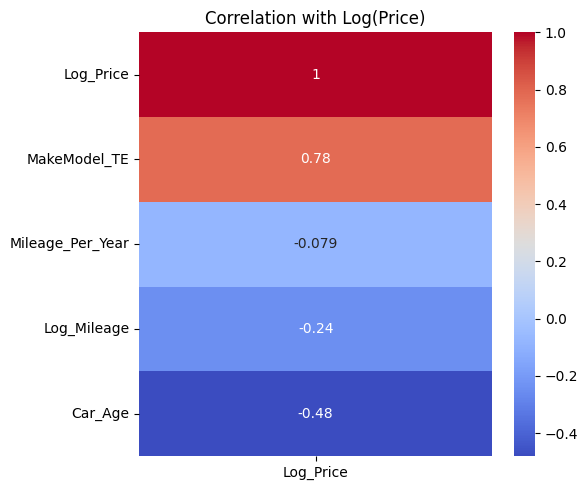

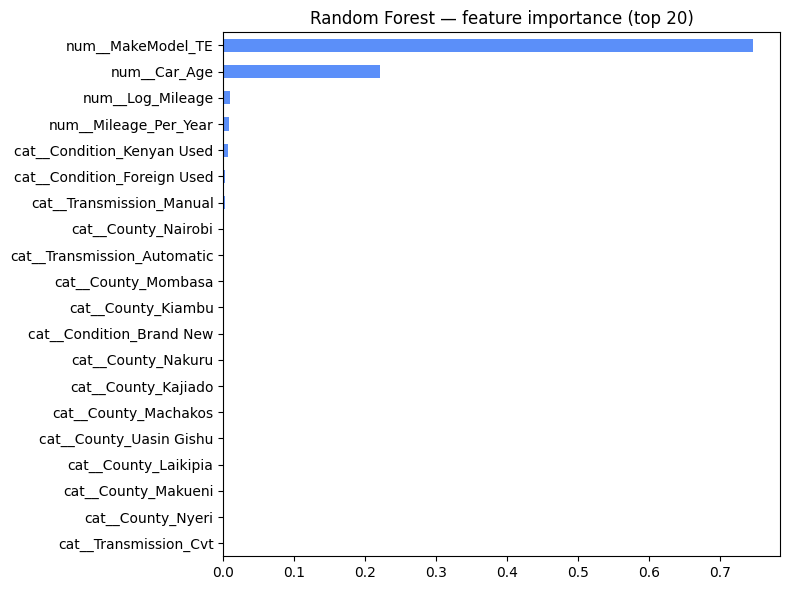

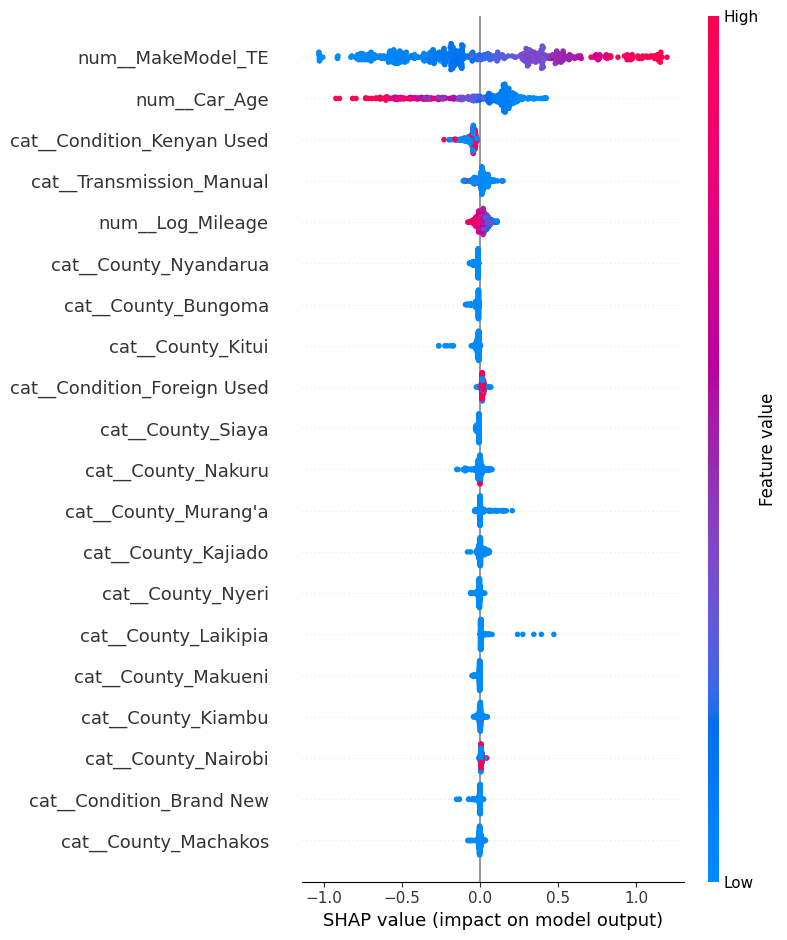

In [15]:
fig, ax = plt.subplots(figsize=(6,5))
corr = train_df[NUMERIC + ["Log_Price"]].corr()
sns.heatmap(corr[["Log_Price"]].sort_values("Log_Price", ascending=False),
            annot=True, cmap="coolwarm", ax=ax)
ax.set_title("Correlation with Log(Price)"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/correlation_log_price.png"); plt.show()

rf_fitted_pipe = rf_grid.best_estimator_
feature_names = rf_fitted_pipe.named_steps["preprocessor"].get_feature_names_out()
importances = pd.Series(rf_fitted_pipe.named_steps["regressor"].feature_importances_,
                         index=feature_names).sort_values()
fig, ax = plt.subplots(figsize=(8,6))
importances.tail(20).plot(kind="barh", ax=ax, color="#5b8ff9")
ax.set_title("Random Forest — feature importance (top 20)"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/rf_feature_importance.png"); plt.show()

xgb_fitted_pipe = xgb_bayes.best_estimator_
X_test_transformed = xgb_fitted_pipe.named_steps["preprocessor"].transform(X_test)
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()
shap_feature_names = xgb_fitted_pipe.named_steps["preprocessor"].get_feature_names_out()
X_test_shap = pd.DataFrame(X_test_transformed, columns=shap_feature_names)

explainer = shap.TreeExplainer(xgb_fitted_pipe.named_steps["regressor"])
sample_n = min(500, len(X_test_shap))
shap_values = explainer.shap_values(X_test_shap.sample(sample_n, random_state=RANDOM_STATE))
shap.summary_plot(shap_values, X_test_shap.sample(sample_n, random_state=RANDOM_STATE))

Rare Segment Definition

In [16]:
seg_counts = df["Make"].value_counts(normalize=True)
rare_makes = seg_counts[seg_counts < 0.02].index.tolist()
train_df["Is_Rare"] = train_df["Make"].isin(rare_makes).astype(int)
test_df["Is_Rare"] = test_df["Make"].isin(rare_makes).astype(int)
print(f"Rare makes: {rare_makes}")
print(f"Share of listings that are rare: {df['Make'].isin(rare_makes).mean()*100:.2f}%")

sample_weight = np.where(train_df["Is_Rare"] == 1, 3.0, 1.0)
xgb_weighted_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor(
        **{k.replace("regressor__", ""): v for k, v in xgb_bayes.best_params_.items()},
        random_state=RANDOM_STATE, n_jobs=-1))
])
xgb_weighted_pipe.fit(X_train, y_train, regressor__sample_weight=sample_weight)
pred_w = xgb_weighted_pipe.predict(X_test)
rmse_w = np.sqrt(mean_squared_error(np.expm1(y_test), np.expm1(pred_w)))
mape_w = mean_absolute_percentage_error(np.expm1(y_test), np.expm1(pred_w))
results["XGBoost (rare-weighted)"] = {"rmse": rmse_w, "mape": mape_w}
print(f"XGBoost (rare-weighted): RMSE={rmse_w:,.0f} MAPE={mape_w:.2%}")

X_train_ohe = preprocessor.fit_transform(X_train)
if hasattr(X_train_ohe, "toarray"):
    X_train_ohe = X_train_ohe.toarray()
ohe_feature_names = preprocessor.get_feature_names_out()
n_train = len(X_train)

X_train_ohe_df = pd.DataFrame(X_train_ohe, columns=ohe_feature_names)
X_train_ohe_df["Is_Rare"] = train_df["Is_Rare"].values
cat_idx = [X_train_ohe_df.columns.get_loc("Is_Rare")]

sm = SMOTENC(categorical_features=cat_idx, random_state=RANDOM_STATE, sampling_strategy=0.3)
X_res, _ = sm.fit_resample(X_train_ohe_df, train_df["Is_Rare"])


y_train_res = np.empty(len(X_res))
y_train_res[:n_train] = y_train.values
knn_y = KNeighborsRegressor(n_neighbors=3).fit(
    X_train_ohe_df.drop(columns=["Is_Rare"]).values, y_train.values)
y_train_res[n_train:] = knn_y.predict(X_res.drop(columns=["Is_Rare"]).values[n_train:])

xgb_smote = XGBRegressor(
    **{k.replace("regressor__", ""): v for k, v in xgb_bayes.best_params_.items()},
    random_state=RANDOM_STATE, n_jobs=-1)
xgb_smote.fit(X_res.drop(columns=["Is_Rare"]), y_train_res)

X_test_ohe = preprocessor.transform(X_test)
if hasattr(X_test_ohe, "toarray"):
    X_test_ohe = X_test_ohe.toarray()
X_test_ohe_df = pd.DataFrame(X_test_ohe, columns=ohe_feature_names, index=X_test.index)
pred_smote = xgb_smote.predict(X_test_ohe_df)
rmse_smote = np.sqrt(mean_squared_error(np.expm1(y_test), np.expm1(pred_smote)))
mape_smote = mean_absolute_percentage_error(np.expm1(y_test), np.expm1(pred_smote))
results["XGBoost (SMOTE-NC)"] = {"rmse": rmse_smote, "mape": mape_smote}
print(f"XGBoost (SMOTE-NC): RMSE={rmse_smote:,.0f} MAPE={mape_smote:.2%}")

Rare makes: ['Land Rover', 'Audi', 'Lexus', 'Ford', 'Daihatsu', 'Volvo', 'Peugeot', 'Jeep', 'Porsche', 'Mini', 'Jaguar', 'Hyundai', 'Kia', 'Chevrolet', 'Alfa Romeo']
Share of listings that are rare: 7.69%
XGBoost (rare-weighted): RMSE=522,768 MAPE=13.96%
XGBoost (SMOTE-NC): RMSE=526,613 MAPE=13.84%


Significance test + disaggregated evaluation

RF (tuned) CV-RMSE:  0.1974 +/- 0.0036
XGB (tuned) CV-RMSE: 0.1983 +/- 0.0039
Paired t-test: t=-1.973, p=0.1198 -> no significant difference

Final model comparison:
                                  rmse      mape
XGBoost (SMOTE-NC)       526613.244018  0.138375
XGBoost (tuned)          519380.851333  0.138847
XGBoost (rare-weighted)  522767.743646  0.139644
Random Forest (tuned)    519320.704606  0.142259
XGBoost                  545448.417297  0.149229
Random Forest            526809.001337  0.149750
Linear Regression        916218.468376  0.246992
Common segment (n=5855): RMSE=474,933  MAPE=13.48%
Rare segment (n=500): RMSE=887,289  MAPE=18.58%


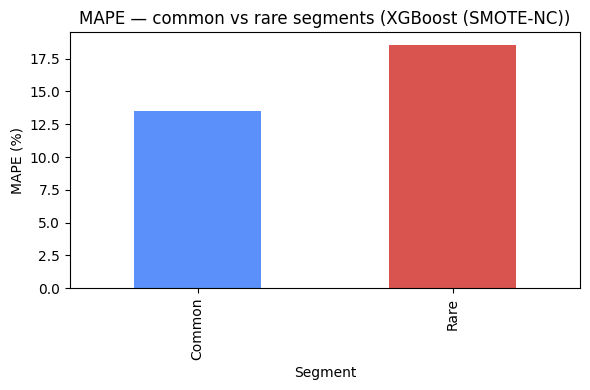

In [17]:
cv_rf = -cross_val_score(rf_grid.best_estimator_, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")
cv_xgb = -cross_val_score(xgb_bayes.best_estimator_, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")
t_stat, p_value = stats.ttest_rel(cv_rf, cv_xgb)
print(f"RF (tuned) CV-RMSE:  {cv_rf.mean():.4f} +/- {cv_rf.std():.4f}")
print(f"XGB (tuned) CV-RMSE: {cv_xgb.mean():.4f} +/- {cv_xgb.std():.4f}")
print(f"Paired t-test: t={t_stat:.3f}, p={p_value:.4f}",
      "-> significant difference" if p_value < 0.05 else "-> no significant difference")

results_df = pd.DataFrame(results).T.sort_values("mape")
print("\nFinal model comparison:"); print(results_df)

best_row_name = results_df.index[0]
best_pipe_map = {"Linear Regression": lr_pipe, "Random Forest": rf_pipe, "XGBoost": xgb_pipe,
                  "Random Forest (tuned)": rf_best_pipe, "XGBoost (tuned)": xgb_best_pipe}
best_pipe = best_pipe_map.get(best_row_name, xgb_best_pipe)
pred_best = best_pipe.predict(X_test)

eval_df = test_df.copy()
eval_df["y_true"] = np.expm1(y_test)
eval_df["y_pred"] = np.expm1(pred_best)
eval_df["abs_pct_err"] = (abs(eval_df["y_true"] - eval_df["y_pred"]) / eval_df["y_true"]) * 100

seg_rows = []
for label, subset in [("Common", eval_df[eval_df["Is_Rare"] == 0]), ("Rare", eval_df[eval_df["Is_Rare"] == 1])]:
    rmse_seg = np.sqrt(mean_squared_error(subset["y_true"], subset["y_pred"]))
    mape_seg = subset["abs_pct_err"].mean()
    seg_rows.append({"Segment": label, "n": len(subset), "RMSE": rmse_seg, "MAPE": mape_seg})
    print(f"{label} segment (n={len(subset)}): RMSE={rmse_seg:,.0f}  MAPE={mape_seg:.2f}%")

fig, ax = plt.subplots(figsize=(6,4))
pd.DataFrame(seg_rows).set_index("Segment")["MAPE"].plot(kind="bar", color=["#5b8ff9", "#d9534f"], ax=ax)
ax.set_title(f"MAPE — common vs rare segments ({best_row_name})"); ax.set_ylabel("MAPE (%)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/rare_vs_common_mape.png"); plt.show()